# Análisis de actividad de PostgreSQL

Este cuaderno consulta estadísticas de la base de datos Joomla y grafica las transacciones confirmadas y revertidas acumuladas desde el último reinicio de PostgreSQL.

In [5]:
import os
import psycopg2
import pandas as pd
import matplotlib.pyplot as plt

connection = psycopg2.connect(
    host="database", port=5432,
    dbname=os.environ["POSTGRES_DB"],
    user=os.environ["POSTGRES_USER"],
    password=os.environ["POSTGRES_PASSWORD"],
)
print("Conexión establecida con PostgreSQL")

Conexión establecida con PostgreSQL


In [6]:
query = """
SELECT datname AS database, numbackends AS active_connections,
       xact_commit AS committed_transactions,
       xact_rollback AS rolled_back_transactions,
       blks_read AS disk_blocks_read, blks_hit AS cache_blocks_hit
FROM pg_stat_database
WHERE datname = current_database();
"""
activity = pd.read_sql_query(query, connection)
activity

/tmp/ipykernel_2186/1859236111.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  activity = pd.read_sql_query(query, connection)


,database,active_connections,committed_transactions,rolled_back_transactions,disk_blocks_read,cache_blocks_hit
0,joomla,3,3402,1,552,127328


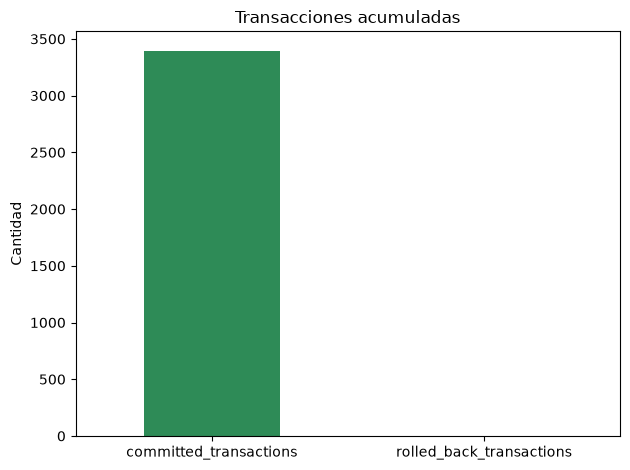

In [3]:
metrics = activity.loc[0, ["committed_transactions", "rolled_back_transactions"]]
metrics.plot(kind="bar", color=["#2e8b57", "#d9534f"], title="Transacciones acumuladas")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
size = pd.read_sql_query("SELECT pg_size_pretty(pg_database_size(current_database())) AS database_size;", connection)
print("Tamaño actual de la base Joomla:", size.loc[0, "database_size"])
connection.close()

Tamaño actual de la base Joomla: 14 MB


/tmp/ipykernel_2186/3577988175.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  size = pd.read_sql_query("SELECT pg_size_pretty(pg_database_size(current_database())) AS database_size;", connection)
